In [1]:
#libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning 
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df_counts= pd.read_csv('property_price_register.csv')

C:\Users\jessi\AppData\Local\Temp\ipykernel_26556\3393397148.py:1: DtypeWarning: Columns (0: property_size) have mixed types. Specify dtype option on import or set low_memory=False.
  df_counts= pd.read_csv('property_price_register.csv')


In [3]:
df_counts.head()

,date_of_sale,address,county,eircode,price_eur,not_full_market_price,vat_exclusive,description,property_size
0,2010-01-01,"5 Braemor Drive, Churchtown, Co.Dublin",Dublin,NaN,343000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
1,2010-01-03,"134 Ashewood Walk, Summerhill Lane, Portlaoise",Laois,NaN,185000.0,False,True,New Dwelling house /Apartment,greater than or equal to 38 sq metres and less...
2,2010-01-04,"59 ormond keep, nenagh",Tipperary,NaN,128000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
3,2010-01-04,"66 Rory O'Connor Place, Arklow",Wicklow,NaN,145000.0,False,False,Second-Hand Dwelling house /Apartment,NaN
4,2010-01-04,"78 Sundays Well Road, Cork",Cork,NaN,510000.0,False,False,Second-Hand Dwelling house /Apartment,NaN


In [4]:
df_counts.shape

(807936, 9)

In [5]:
df_counts.columns.tolist()

['date_of_sale',
 'address',
 'county',
 'eircode',
 'price_eur',
 'not_full_market_price',
 'vat_exclusive',
 'description',
 'property_size']

In [6]:
df_counts.info()

<class 'pandas.DataFrame'>
RangeIndex: 807936 entries, 0 to 807935
Data columns (total 9 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   date_of_sale           807936 non-null  str    
 1   address                807936 non-null  str    
 2   county                 807936 non-null  str    
 3   eircode                251432 non-null  str    
 4   price_eur              807936 non-null  float64
 5   not_full_market_price  807936 non-null  bool   
 6   vat_exclusive          807936 non-null  bool   
 7   description            807936 non-null  str    
 8   property_size          52608 non-null   str    
dtypes: bool(2), float64(1), str(6)
memory usage: 117.1 MB


In [7]:
print(df_counts.isnull().sum())

date_of_sale                  0
address                       0
county                        0
eircode                  556504
price_eur                     0
not_full_market_price         0
vat_exclusive                 0
description                   0
property_size            755328
dtype: int64


In [8]:
df_counts['county'].value_counts().head(20)

county
Dublin       253128
Cork          89418
Kildare       44108
Galway        38940
Meath         33593
Limerick      29601
Wexford       28232
Wicklow       27316
Louth         22754
Waterford     22129
Kerry         21898
Tipperary     21586
Donegal       21405
Mayo          19209
Clare         18057
Westmeath     15620
Laois         13446
Kilkenny      13050
Cavan         11912
Sligo         11751
Name: count, dtype: int64

In [9]:
df_Sligo = df_counts[df_counts['county'].astype(str).str.contains('Sligo', case=False, na=False)].copy()


In [10]:
df_Sligo["county"].unique()

<ArrowStringArray>
['Sligo']
Length: 1, dtype: str

In [11]:
df = df_Sligo.copy()

In [12]:
#  choose the Count of Sligo because has the smallest dataset
df_Sligo = df[df['county'].astype(str).str.contains('Sligo', case=False, na=False )].copy()

print("Rows in Sligo:", len(df_Sligo))
print(df_Sligo.head())

Rows in Sligo: 11751
    date_of_sale                                      address county eircode  \
40    2010-01-04                  4 Hawthorn Court, Collooney  Sligo     NaN   
102   2010-01-06                 25 Markievicz Heights, Sligo  Sligo     NaN   
157   2010-01-08                           Rathquarter, Sligo  Sligo     NaN   
198   2010-01-08  28  Temple Manor, Balllinacarrow, Co. Sligo  Sligo     NaN   
261   2010-01-12      Kevinsfort Park, Strandhill Road, Sligo  Sligo     NaN   

     price_eur  not_full_market_price  vat_exclusive  \
40    220000.0                  False          False   
102   227000.0                  False          False   
157    12000.0                   True          False   
198   200000.0                  False           True   
261   300000.0                   True          False   

                               description               property_size  
40   Second-Hand Dwelling house /Apartment                         NaN  
102  Second-Han

In [13]:
df_Sligo.columns

Index(['date_of_sale', 'address', 'county', 'eircode', 'price_eur',
       'not_full_market_price', 'vat_exclusive', 'description',
       'property_size'],
      dtype='str')

In [14]:
print(df_Sligo.dtypes)

date_of_sale                 str
address                      str
county                       str
eircode                      str
price_eur                float64
not_full_market_price       bool
vat_exclusive               bool
description                  str
property_size                str
dtype: object


In [15]:
print(df_Sligo.isnull().sum())

date_of_sale                 0
address                      0
county                       0
eircode                   8183
price_eur                    0
not_full_market_price        0
vat_exclusive                0
description                  0
property_size            11026
dtype: int64


In [16]:
print(df_Sligo["property_size"].unique()[:20])

<ArrowStringArray>
[                                                                nan,
                                        'greater than 125 sq metres',
 'greater than or equal to 38 sq metres and less than 125 sq metres',
                                            'less than 38 sq metres',
                            'greater than or equal to 125 sq metres']
Length: 5, dtype: str


In [17]:
df["price_eur"] = pd.to_numeric(df["price_eur"], errors="coerce")
df = df.dropna(subset=["price_eur"])

# Remove the top 5% most expensive sales
limit = df["price_eur"].quantile(0.95)
df = df[df["price_eur"] <= limit]

print("Rows before:", len(df_Sligo))
print("Rows kept:", len(df))
print("Max price now:", df["price_eur"].max())
print(df["county"].unique())   # must show only Sligo

Rows before: 11751
Rows kept: 11163
Max price now: 403832.0
<ArrowStringArray>
['Sligo']
Length: 1, dtype: str


In [18]:
X = df[['not_full_market_price', 'vat_exclusive', 'description',
        'property_size', 'date_of_sale', 'address']].copy()
y = df['price_eur']

print(X.shape, y.shape)

(11163, 6) (11163,)


In [19]:
print(X.columns.tolist())

['not_full_market_price', 'vat_exclusive', 'description', 'property_size', 'date_of_sale', 'address']


In [20]:
# description: 1 = new dwelling, 0 = second-hand (English and Irish versions)
X["is_new"] = X["description"].str.contains("New|Nua", case=False, regex=True).astype(int)
X = X.drop(columns=["description"])

# property_size: ordinal category (0 = unknown)
def size_cat(s):
    if pd.isna(s):
        return 0
    s = str(s).lower()
    if "less than 38" in s:
        return 1
    if "38" in s and "125" in s:
        return 2
    if "125" in s:
        return 3
    return 0

X["property_size"] = X["property_size"].apply(size_cat)

# date_of_sale: year and month
dates = pd.to_datetime(X["date_of_sale"], errors="coerce")
X["year"] = dates.dt.year
X["month"] = dates.dt.month
X = X.drop(columns=["date_of_sale"])
print("Invalid dates:", dates.isnull().sum())
X["year"] = X["year"].fillna(X["year"].median())
X["month"] = X["month"].fillna(X["month"].median())

# address: locality from a list of known places in Sligo
towns = ["collooney", "strandhill", "tubbercurry", "ballymote", "enniscrone",
         "rosses point", "grange", "easkey", "riverstown", "ballisodare",
         "dromore west", "coolaney", "ballinacarrow", "mullaghmore",
          "cliffoney", "gurteen", "bunninadden", "geevagh", "aclare",
         "culfadda", "achonry", "drumcliff"]

def get_locality(addr):
    if pd.isna(addr):
        return "Unknown"
    a = str(addr).lower()
    for t in towns:
        if t in a:
            return t.title()
    return "Sligo (other)"

X["locality"] = X["address"].apply(get_locality)
X = X.drop(columns=["address"])
print(X["locality"].value_counts())

X = pd.get_dummies(X, columns=["not_full_market_price", "vat_exclusive", "locality"], dtype=int)

print(X.shape)
print("Text columns left:", X.select_dtypes(exclude="number").columns.tolist())   # must be []
print("Nulls:", X.isnull().sum().sum())

Invalid dates: 0
locality
Sligo (other)    5712
Ballymote         823
Strandhill        690
Tubbercurry       639
Ballisodare       595
Enniscrone        524
Collooney         478
Coolaney          326
Gurteen           198
Grange            166
Cliffoney         165
Riverstown        150
Easkey            145
Rosses Point      143
Dromore West       84
Geevagh            69
Mullaghmore        60
Ballinacarrow      59
Aclare             54
Drumcliff          44
Culfadda           19
Bunninadden        11
Achonry             9
Name: count, dtype: int64
(11163, 31)
Text columns left: []
Nulls: 0


In [21]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, median_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.compose import TransformedTargetRegressor
import numpy as np
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("y_test max:", y_test.max())

baseline = DummyRegressor(strategy="median").fit(X_train, y_train)
print("MAE baseline:", round(mean_absolute_error(y_test, baseline.predict(X_test))))

y_test max: 400000.0
MAE baseline: 73503


In [22]:
for d in [4, 6, 8, 10, 12]:
    m = DecisionTreeRegressor(max_depth=6, random_state=42).fit(X_train, y_train)
    p = m.predict(X_test)
    print(d, "| MAE:", round(mean_absolute_error(y_test, p)),
          "| R² train:", round(m.score(X_train, y_train), 3),
          "| R² test:", round(r2_score(y_test, p), 3))

4 | MAE: 57644 | R² train: 0.358 | R² test: 0.343
6 | MAE: 57644 | R² train: 0.358 | R² test: 0.343
8 | MAE: 57644 | R² train: 0.358 | R² test: 0.343
10 | MAE: 57644 | R² train: 0.358 | R² test: 0.343
12 | MAE: 57644 | R² train: 0.358 | R² test: 0.343


In [23]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

dt_Regressor = DecisionTreeRegressor(max_depth = 6, random_state=42)

# Train the model
dt_Regressor.fit(X_train, y_train)




,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

In [24]:
y_pred = dt_Regressor.predict(X_test)
result_df = pd.DataFrame({'Actual': y_test.values, 'Predicted': y_pred})
print(result_df)

        Actual      Predicted
0      68000.0  105471.348705
1      50000.0  105471.348705
2     149000.0  138881.695775
3     226000.0  207478.097070
4     260000.0  207478.097070
...        ...            ...
2228  198000.0  105471.348705
2229   75000.0  105471.348705
2230  190000.0  138881.695775
2231  140969.0  138881.695775
2232   77500.0  138881.695775

[2233 rows x 2 columns]


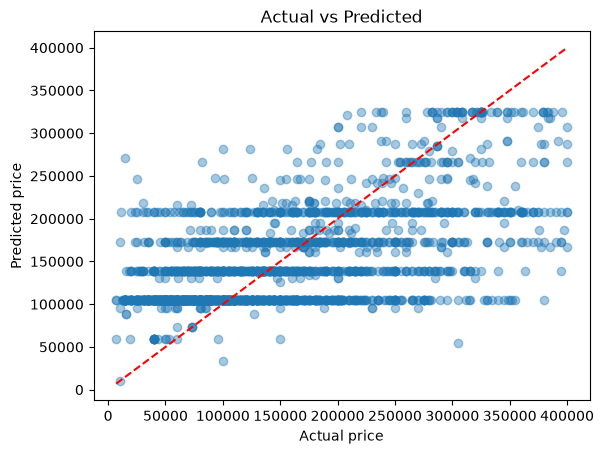

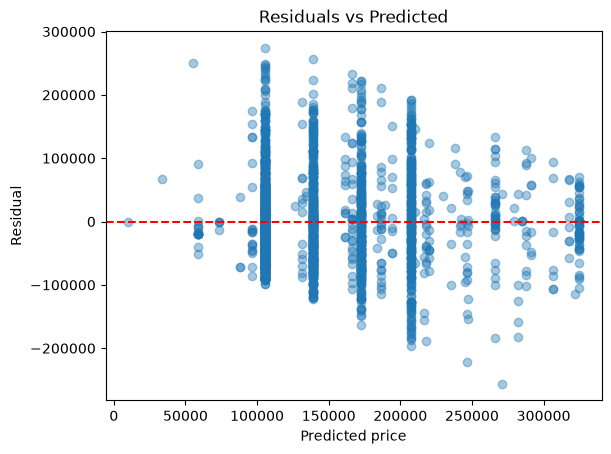

In [25]:
import matplotlib.pyplot as plt

# Actual vs predicted (the closer to the line, the better)
plt.scatter(y_test, y_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs Predicted")
plt.show()

# Residuals (errors): they should be centred around 0, with no pattern
residuals = y_test - y_pred
plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted price")
plt.ylabel("Residual")
plt.title("Residuals vs Predicted")
plt.show()

In [26]:

print("MAE :", mean_absolute_error(y_test, y_pred))
print('Median:', median_absolute_error(y_test, y_pred) )
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²  :", r2_score(y_test, y_pred))



MAE : 57643.60903432223
Median: 48471.348704735385
RMSE: 74040.35267008592
R²  : 0.34325215964583056


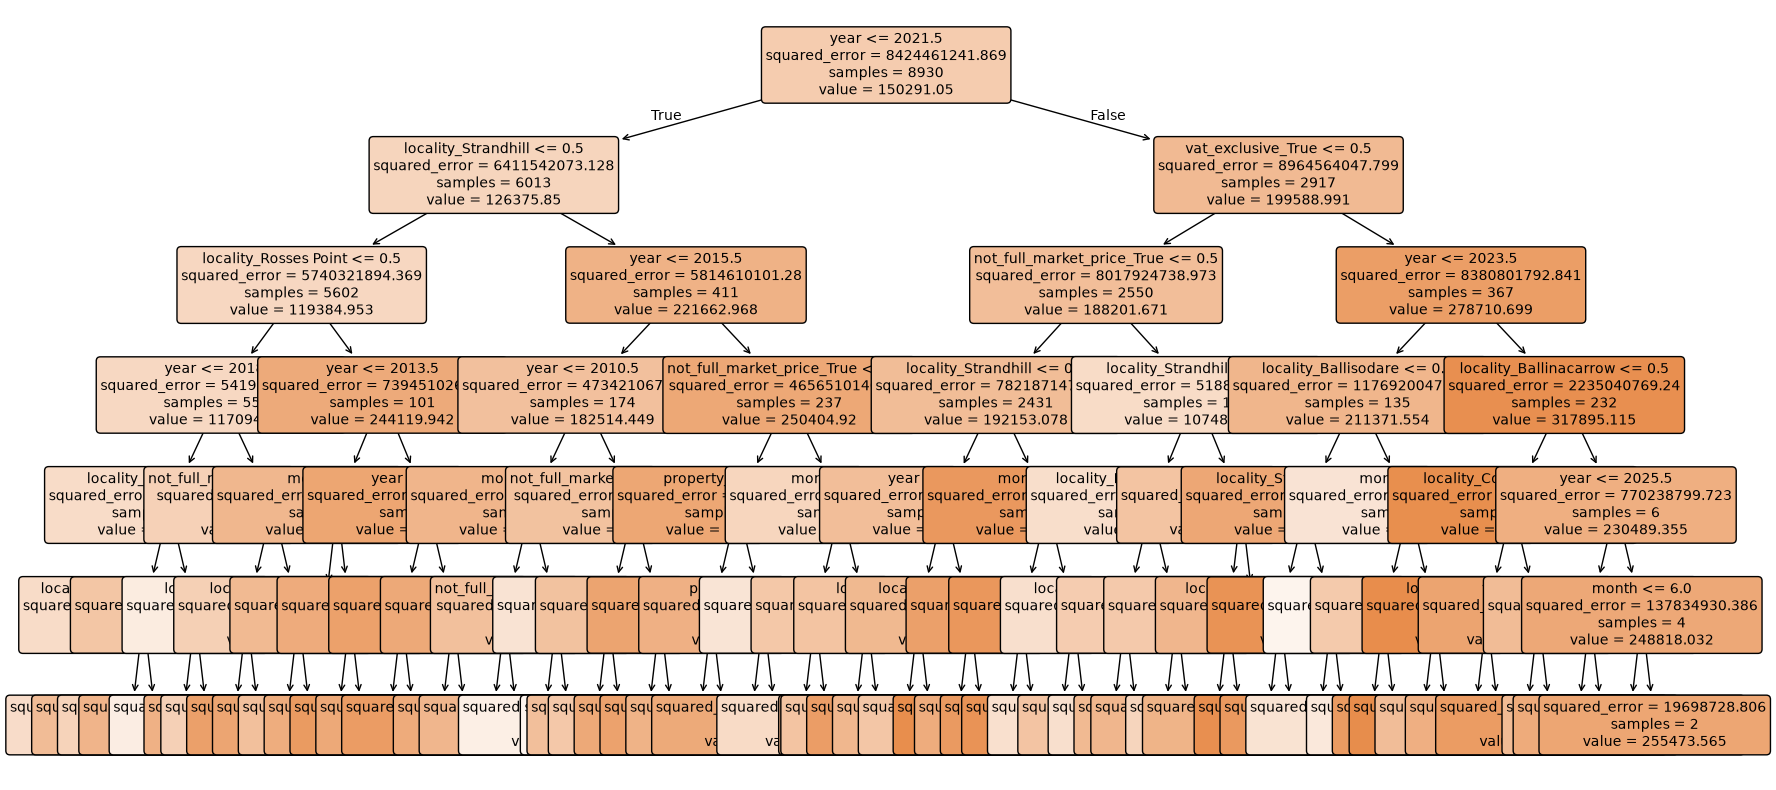

In [27]:
plt.figure(figsize=(20, 10))
plot_tree(dt_Regressor, filled=True, feature_names=X.columns.tolist(), class_names=df['price_eur'].unique().astype(str).tolist(), rounded=True, fontsize=10)
plt.show()

In [28]:
importances = pd.Series(dt_Regressor.feature_importances_, index=X_train.columns)
print(importances.sort_values(ascending=False).head(10))

year                           0.521728
locality_Strandhill            0.187977
vat_exclusive_True             0.097575
locality_Rosses Point          0.059414
not_full_market_price_True     0.035385
locality_Ballisodare           0.025443
locality_Grange                0.016151
not_full_market_price_False    0.014907
locality_Drumcliff             0.008364
locality_Mullaghmore           0.008169
dtype: float64


In [29]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, median_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1)

# Train the model
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

print("MAE      :", round(mean_absolute_error(y_test, y_pred_rf)))
print("Median AE:", round(median_absolute_error(y_test, y_pred_rf)))
print("RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred_rf))))
print("R²       :", round(r2_score(y_test, y_pred_rf), 3))

MAE      : 55251
Median AE: 44730
RMSE     : 71776
R²       : 0.383


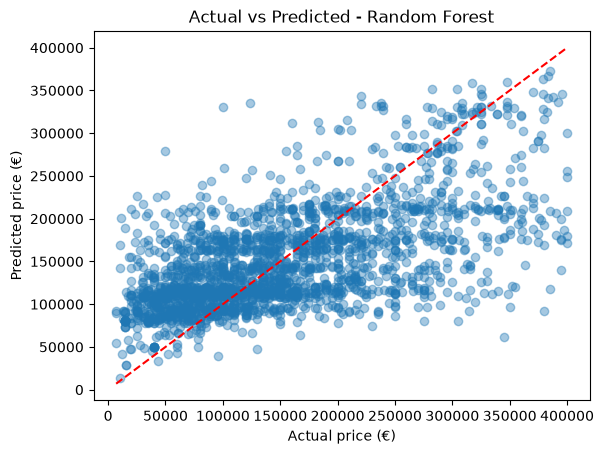

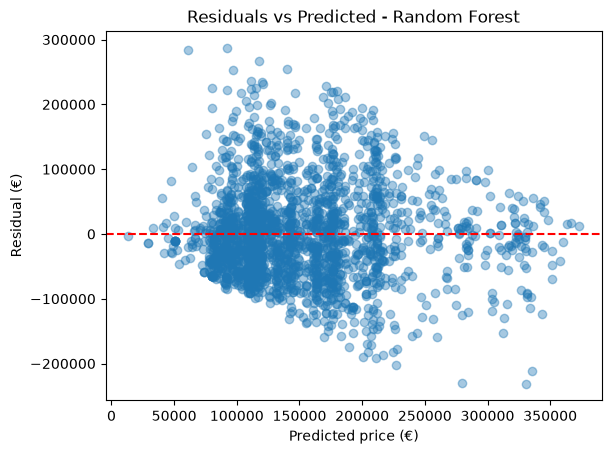

In [30]:
import matplotlib.pyplot as plt

# Actual vs predicted (the closer to the red line, the better)
plt.scatter(y_test, y_pred_rf, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual price (€)")
plt.ylabel("Predicted price (€)")
plt.title("Actual vs Predicted - Random Forest")
plt.show()

# Residuals (actual - predicted): they should be centred around 0, with no pattern
residuals_rf = y_test - y_pred_rf
plt.scatter(y_pred_rf, residuals_rf, alpha=0.4)
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted price (€)")
plt.ylabel("Residual (€)")
plt.title("Residuals vs Predicted - Random Forest")
plt.show()

In [31]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, median_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)

print("MAE      :", round(mean_absolute_error(y_test, y_pred_lr)))
print("Median AE:", round(median_absolute_error(y_test, y_pred_lr)))
print("RMSE     :", round(np.sqrt(mean_squared_error(y_test, y_pred_lr))))
print("R²       :", round(r2_score(y_test, y_pred_lr), 3))

MAE      : 60594
Median AE: 51201
RMSE     : 76417
R²       : 0.3


In [32]:
X_lr = pd.get_dummies(X, columns=["year"], dtype=int)

X_train_lr, X_test_lr, y_train_lr, y_test_lr = train_test_split(
    X_lr, y, test_size=0.2, random_state=42
)

lr_model2 = LinearRegression().fit(X_train_lr, y_train_lr)
y_pred_lr2 = lr_model2.predict(X_test_lr)

print("MAE:", round(mean_absolute_error(y_test_lr, y_pred_lr2)))
print("R² :", round(r2_score(y_test_lr, y_pred_lr2), 3))

MAE: 57026
R² : 0.365
